In [26]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [27]:
df=pd.read_csv('Fish.csv')
df.head()

,Species,Weight,Length1,Length2,Length3,Height,Width
0,Bream,242.0,23.2,25.4,30.0,11.5200,4.0200
1,Bream,290.0,24.0,26.3,31.2,12.4800,4.3056
2,Bream,340.0,23.9,26.5,31.1,12.3778,4.6961
3,Bream,363.0,26.3,29.0,33.5,12.7300,4.4555
4,Bream,430.0,26.5,29.0,34.0,12.4440,5.1340


In [28]:
df.dtypes

Species     object
Weight     float64
Length1    float64
Length2    float64
Length3    float64
Height     float64
Width      float64
dtype: object

In [29]:
df.isna().sum()

Species    0
Weight     0
Length1    0
Length2    0
Length3    0
Height     0
Width      0
dtype: int64

In [30]:
df.duplicated().sum()

np.int64(0)

In [6]:
#1. Crear una nueva columna que incluya el volumen del pez, asumiendo el calculo como si fuera un cilindro

In [31]:
df['Volumen']=round(np.pi*df['Height']*(df['Width']/2)**2,4)

In [32]:
df.describe()

,Weight,Length1,Length2,Length3,Height,Width,Volumen
count,159.000000,159.000000,159.000000,159.000000,159.000000,159.000000,159.000000
mean,398.326415,26.247170,28.415723,31.227044,8.970994,4.417486,195.209923
std,357.978317,9.996441,10.716328,11.610246,4.286208,1.685804,181.496306
min,0.000000,7.500000,8.400000,8.800000,1.728400,1.047600,1.498800
25%,120.000000,19.050000,21.000000,23.150000,5.944800,3.385650,56.688600
50%,273.000000,25.200000,27.300000,29.400000,7.786000,4.248500,109.061100
75%,650.000000,32.700000,35.500000,39.650000,12.365900,5.584500,324.822550
max,1650.000000,59.000000,63.400000,68.000000,18.957000,8.142000,671.053800


In [9]:
#2. Verifica la correlación posible entre las variables, numérica y gráficamente. 
# ¿Aumenta la correlación entre el peso y longitudes de los peces, altura y ancho al
# añadir el volumen? Explica.


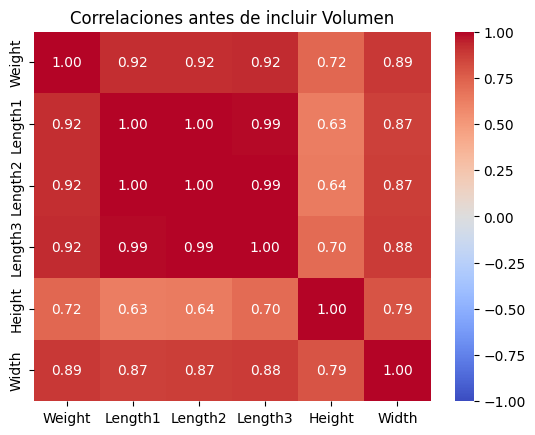

In [33]:
corr_antes = df[['Weight','Length1','Length2','Length3','Height','Width']].corr()
sns.heatmap(corr_antes,annot=True,vmax=1,vmin=-1,cmap='coolwarm',fmt='.2f')
plt.title('Correlaciones antes de incluir Volumen')
plt.show()

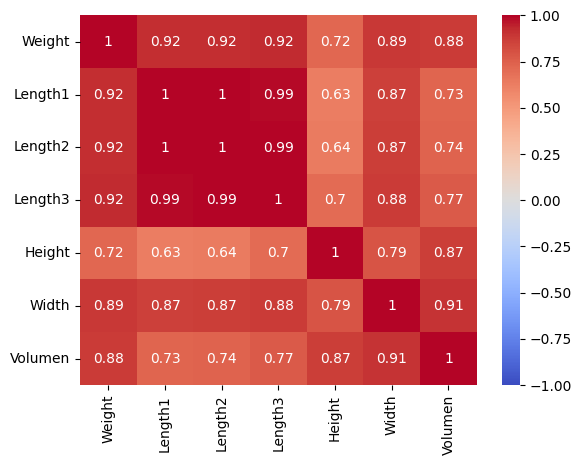

In [34]:
df_numeric = df.select_dtypes(include = np.number)
sns.heatmap(df_numeric.corr(),vmin=-1,vmax=1,annot=True,cmap='coolwarm', )
plt.show()

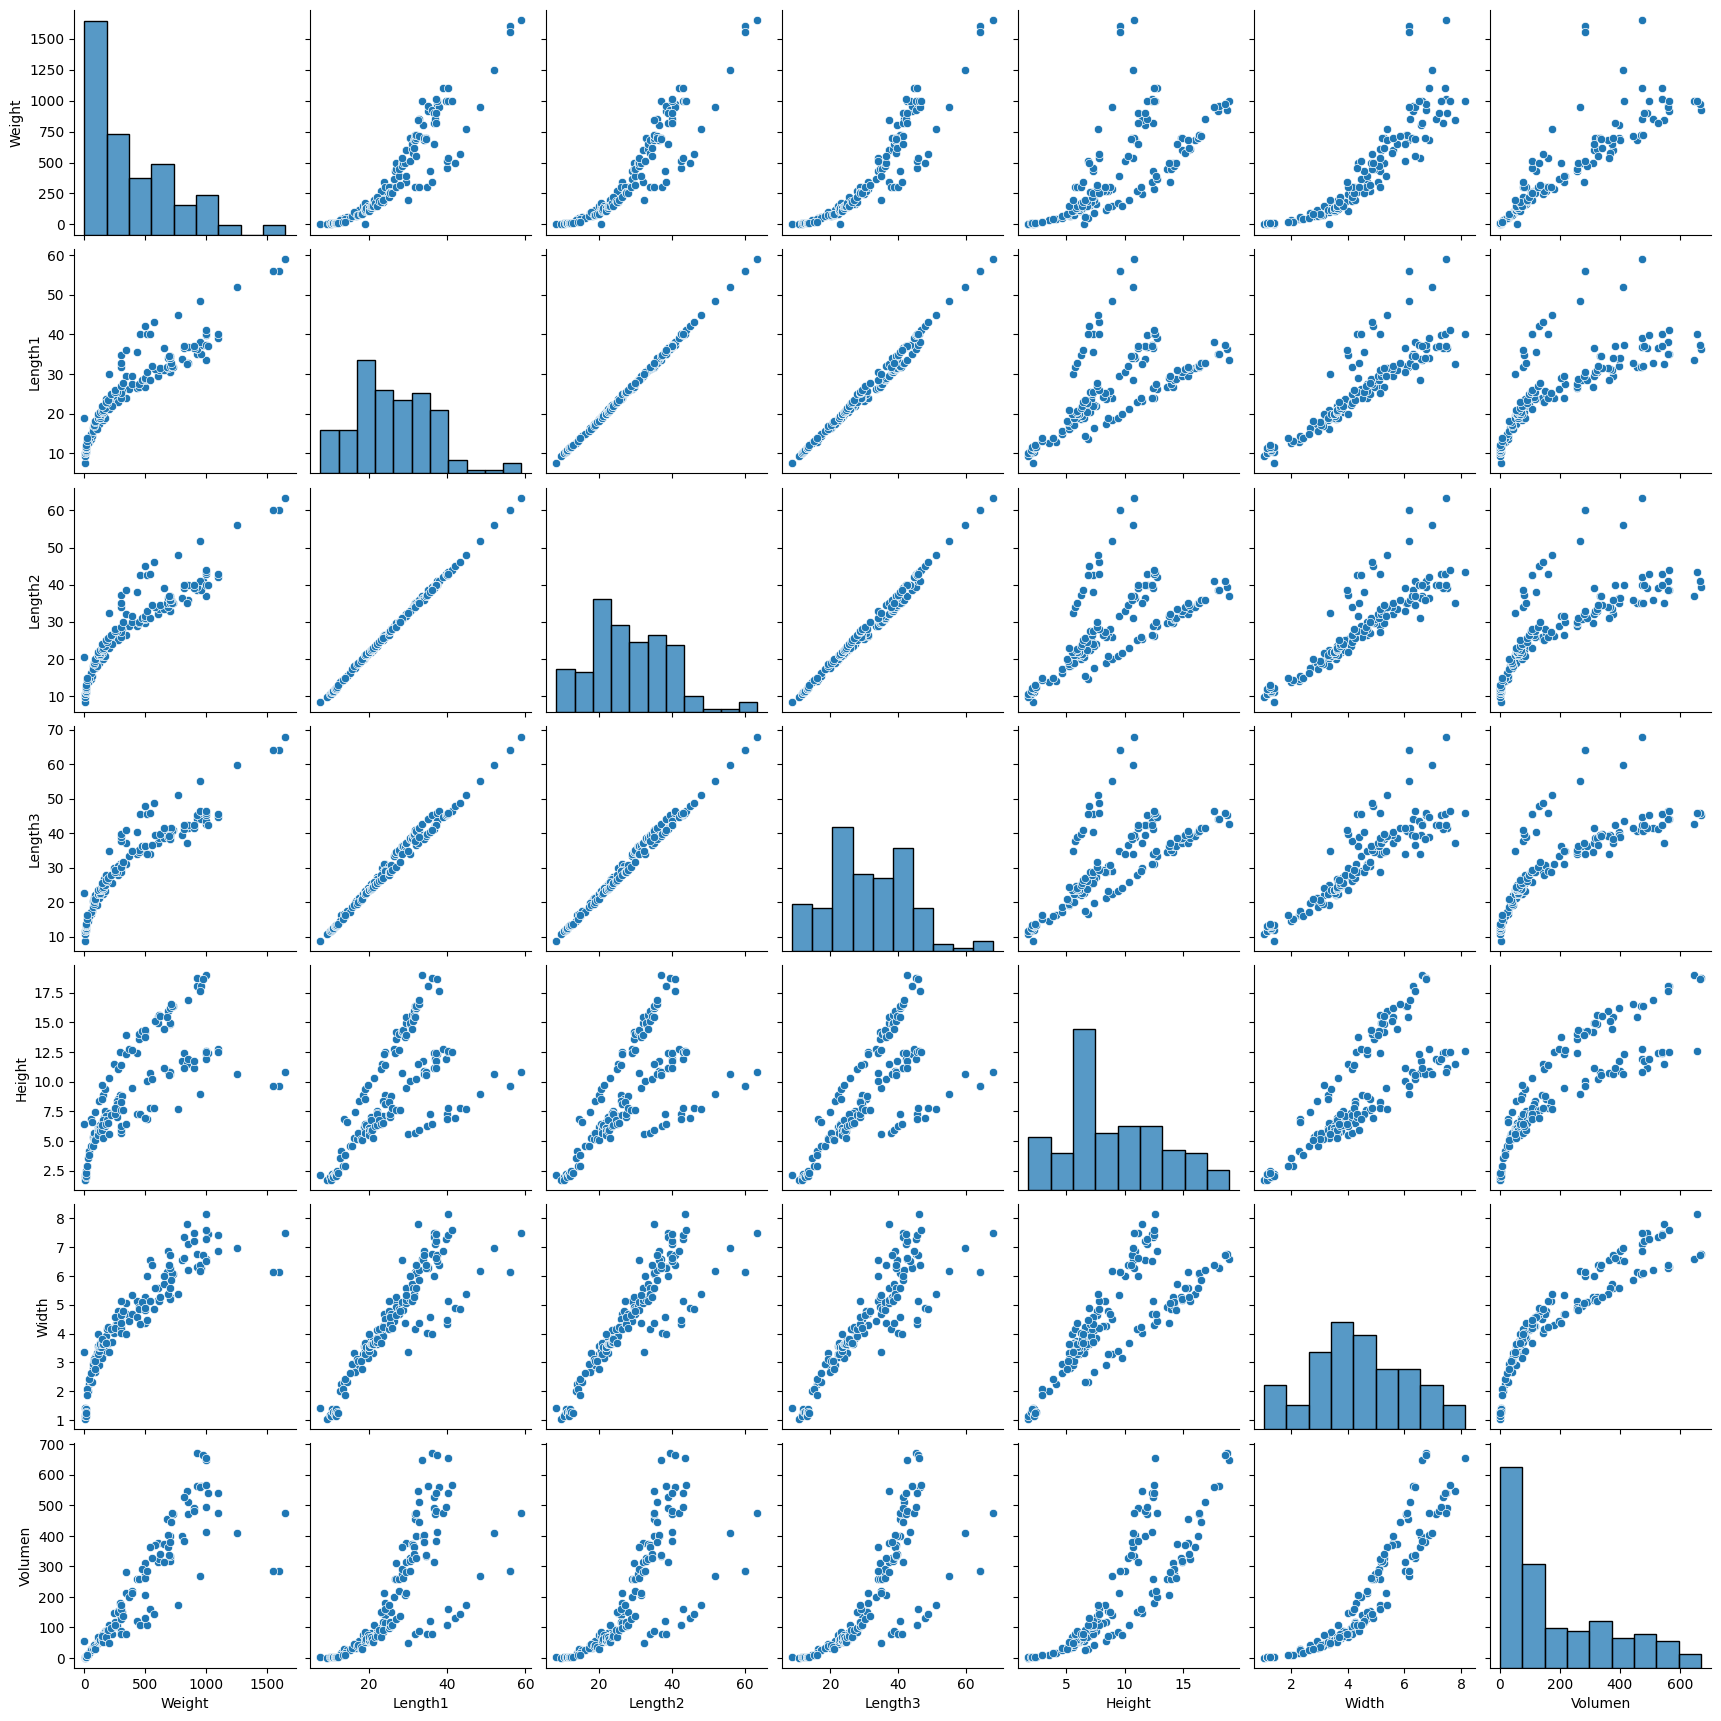

In [35]:
sns.pairplot(df_numeric)

In [36]:
"""
Se observan correlaciones altas y positivas del peso con el resto de las variables, siendo las longitudes
las que presentan las correlaciones mas altas (0.92). Por otra parte, al incluir la variable volumen
(que deriva de las variables weight y height) no se observan variaciones en las correlaciones.
"""

'\nSe observan correlaciones altas y positivas del peso con el resto de las variables, siendo las longitudes\nlas que presentan las correlaciones mas altas (0.92). Por otra parte, al incluir la variable volumen\n(que deriva de las variables weight y height) no se observan variaciones en las correlaciones.\n'

In [37]:
# 3. Construye un modelo de regresión lineal que relacione el volumen y el peso de los
# peces. Realiza una breve evaluación del modelo y grafícalo.


In [38]:
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm

In [39]:
def regresion(dataframe, variables_independientes, variable_dependiente):
  X = dataframe[variables_independientes]
  y = dataframe[variable_dependiente]

  #Agregar una constante al predictor
  X = sm.add_constant(X)

  #Modelo de Regresión Lineal
  model = sm.OLS(y, X).fit()
  summary = model.summary()
  predictions = model.predict(X)

  #Error Cuadrático Medio (MSE: Mean Squared Error)
  mse = ((y - predictions)**2).mean()

  #Raiz del Error Cuadrático Medio (RMSE: Root Mean Squared Error)
  rmse = np.sqrt(mse)

    #Coeficiente de Determinación
  r_squared = model.rsquared

  #Error Absoluto Medio (MAE)
  mae = abs(y - predictions).mean()

  metrics_dict = {
      "Coeficiente de Determinación (R^2)": r_squared,
      "Error Cuadrático Medio (MSE)": mse,
      "Raíz de Error Cuadrático Medio (RMSE)": rmse,
      "Error Absoluto Medio (MAE)": mae
  }

  #Retornar el diccionario y el gráfico en una lista
  return [metrics_dict, dataframe[variables_independientes[0]], y, predictions, summary]

In [40]:
results = regresion(df_numeric, ["Volumen"], "Weight")

metrics_dict = results[0]

for key, value in metrics_dict.items():
  print(f"{key}: {value:.2f}")

Coeficiente de Determinación (R^2): 0.78
Error Cuadrático Medio (MSE): 28283.91
Raíz de Error Cuadrático Medio (RMSE): 168.18
Error Absoluto Medio (MAE): 90.97


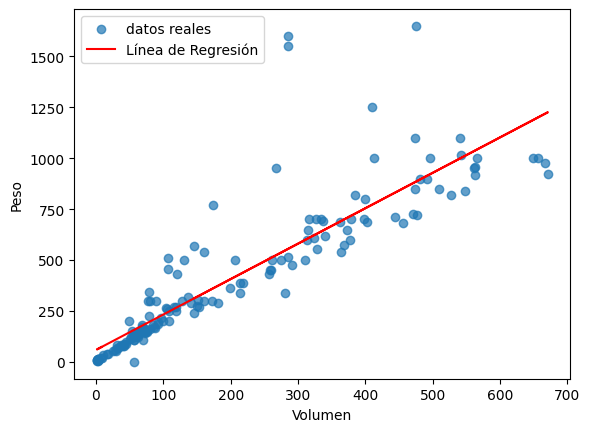

In [41]:
x_data = results[1]
y_data = results[2]
y_predictions = results[3]

plt.scatter(x_data, y_data, label = 'datos reales', alpha = 0.7)
plt.plot(x_data, y_predictions, color = 'red', label = 'Línea de Regresión')
plt.legend()
plt.xlabel("Volumen")
plt.ylabel("Peso")
plt.show()

In [19]:
""""
La variable Volumen es capaz de explicar aproximadamente el 78% de la variabilidad del peso de los peces.
Además, el modelo presenta un MAE de 90.97 gramos, valor que resulta razonable considerando
que el 50% central de los pesos de la muestra se encuentra entre 120 y 650 gramos, 
con un rango intercuartílico (IQR) de 530 gramos.
Gráficamente se observa una relación lineal positiva entre el volumen y el peso,
donde la mayoría de los datos se ajustan a la recta de regresión. 
No obstante, existen algunos puntos alejados de la línea, principalmente en peces de mayor tamaño,
lo que indica que otras variables o las diferencias entre especies también influyen
en el peso de los peces.
"""

'"\nLa variable Volumen es capaz de explicar aproximadamente el 78% de la variabilidad del peso de los peces.\nAdemás, el modelo presenta un MAE de 90.97 gramos, valor que resulta razonable considerando\nque el 50% central de los pesos de la muestra se encuentra entre 120 y 650 gramos, \ncon un rango intercuartílico (IQR) de 530 gramos.\nGráficamente se observa una relación lineal positiva entre el volumen y el peso,\ndonde la mayoría de los datos se ajustan a la recta de regresión. \nNo obstante, existen algunos puntos alejados de la línea, principalmente en peces de mayor tamaño,\nlo que indica que otras variables o las diferencias entre especies también influyen\nen el peso de los peces.\n'

In [20]:
# 4. ¿Qué sucede si aplicas el modelo anterior por separado a cada especie de peces?  Explica.

In [42]:
for especie in df['Species'].unique():

    print(f"Especie: {especie}")

    df_esp = df[df['Species'] == especie]

    results = regresion(df_esp, ['Volumen'], 'Weight')

    metrics_dict = results[0]

    for key, value in metrics_dict.items():
        print(f"{key}: {value:.2f}")

    print("\n")

Especie: Bream
Coeficiente de Determinación (R^2): 0.90
Error Cuadrático Medio (MSE): 4348.35
Raíz de Error Cuadrático Medio (RMSE): 65.94
Error Absoluto Medio (MAE): 53.69


Especie: Roach
Coeficiente de Determinación (R^2): 0.89
Error Cuadrático Medio (MSE): 835.83
Raíz de Error Cuadrático Medio (RMSE): 28.91
Error Absoluto Medio (MAE): 16.00


Especie: Whitefish
Coeficiente de Determinación (R^2): 0.86
Error Cuadrático Medio (MSE): 11147.58
Raíz de Error Cuadrático Medio (RMSE): 105.58
Error Absoluto Medio (MAE): 69.80


Especie: Parkki
Coeficiente de Determinación (R^2): 1.00
Error Cuadrático Medio (MSE): 25.59
Raíz de Error Cuadrático Medio (RMSE): 5.06
Error Absoluto Medio (MAE): 4.47


Especie: Perch
Coeficiente de Determinación (R^2): 0.97
Error Cuadrático Medio (MSE): 3835.98
Raíz de Error Cuadrático Medio (RMSE): 61.94
Error Absoluto Medio (MAE): 40.18


Especie: Pike
Coeficiente de Determinación (R^2): 0.84
Error Cuadrático Medio (MSE): 36222.42
Raíz de Error Cuadrático Medi

c:\Users\cgadv\anaconda3\envs\desafiolatam2\Lib\site-packages\statsmodels\stats\stattools.py:74: ValueWarning: omni_normtest is not valid with less than 8 observations; 6 samples were given.
  warn("omni_normtest is not valid with less than 8 observations; %i "


c:\Users\cgadv\anaconda3\envs\desafiolatam2\Lib\site-packages\statsmodels\stats\stattools.py:74: ValueWarning: omni_normtest is not valid with less than 8 observations; 6 samples were given.
  warn("omni_normtest is not valid with less than 8 observations; %i "


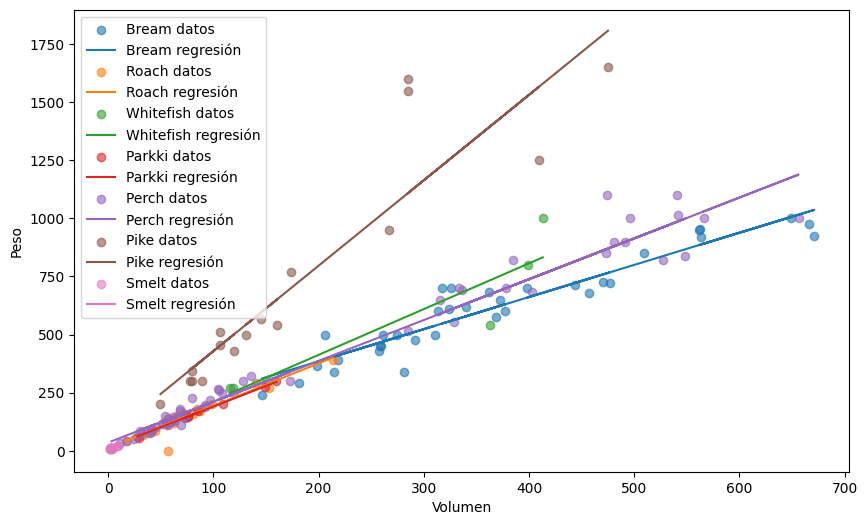

In [47]:
plt.figure(figsize=(10,6))
for especie in df['Species'].unique():

    df_esp = df[df['Species'] == especie]

    results = regresion(df_esp, ['Volumen'], 'Weight')

    x_data = results[1]
    y_data = results[2]
    y_predictions = results[3]

    plt.scatter(x_data, y_data, alpha=0.6, label=f'{especie} datos')
    plt.plot(x_data, y_predictions, label=f'{especie} regresión')

plt.xlabel('Volumen')
plt.ylabel('Peso')
plt.legend()
plt.show()

In [ ]:
"""
Al comparar los resultados, se observa que el modelo mejora bastante cuando se aplica por separado
a cada especie de pez en lugar de usar un único modelo para todos.
En general, los valores de R**2 aumentan en casi todas las especies, 
lo que indica que el modelo explica mejor el peso cuando se analiza cada tipo de pez por separado. 
También se observa que los errores (MAE, RMSE y MSE) tienden a ser menores o más controlados 
en varios casos, especialmente en especies como Parkki y Perch.
Gráficamente, se aprecia que cada especie presenta una relación propia entre el volumen y el peso,
reflejada en pendientes distintas para las rectas de regresión. Algunas especies, como Pike,
muestran un aumento del peso mucho más pronunciado a medida que aumenta el volumen,
mientras que otras presentan una relación más moderada.
En cambio, el modelo general (con todos los peces juntos) tiene un desempeño más bajo,
lo que sugiere que no todas las especies siguen exactamente el mismo patrón de crecimiento y
que agruparlas en un único modelo dificulta la predicción del peso.
En resumen, separar el análisis por especie permite obtener predicciones más precisas y
resultados más consistentes.
"""

In [ ]:
#5. Construye un modelo de regresión que relacione dos o más variables con el peso de
# los peces. Realiza una breve evaluación del modelo.


In [ ]:
# Variables
X = df[['Length3', 'Height', 'Width']]
y = df['Weight']

# Agregar constante
X = sm.add_constant(X)

# Modelo
model = sm.OLS(y, X).fit()

# Predicciones
pred = model.predict(X)

# Métricas
mse = np.mean((y - pred)**2)
rmse = np.sqrt(mse)
mae = np.mean(abs(y - pred))
r2 = model.rsquared

print(f"R²: {r2:.2f}")
print(f"MSE: {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"MAE: {mae:.2f}")

R²: 0.88
MSE: 15556.06
RMSE: 124.72
MAE: 96.79
